# Optimized IoT vs. Non-IoT Classification

This notebook replaces the source-only traffic representation with a clean,
bidirectional per-device representation. It uses explicit endpoint labels,
excludes infrastructure and unknown MAC addresses from training, caches the
expensive feature extraction, and evaluates both temporal generalization and
generalization to unseen devices.

The goal is a reproducible and leakage-aware evaluation—not an artificial
100% accuracy target.

In [1]:
# This cell must run before importing matplotlib/seaborn.
import os
import sys
import tempfile
from pathlib import Path

EXPECTED_PYTHON = Path(
    "/Users/duongtuanhoang/anaconda3/envs/experiment/bin/python"
).resolve()
ACTUAL_PYTHON = Path(sys.executable).resolve()

if ACTUAL_PYTHON != EXPECTED_PYTHON:
    raise RuntimeError(
        "This notebook must run in the Conda environment 'experiment'. "
        f"Expected {EXPECTED_PYTHON}, got {ACTUAL_PYTHON}."
    )

runtime_cache = Path(tempfile.gettempdir()) / "iot-classifier-experiment-cache"
mpl_cache = runtime_cache / "matplotlib"
xdg_cache = runtime_cache / "xdg"
mpl_cache.mkdir(parents=True, exist_ok=True)
xdg_cache.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(mpl_cache)
os.environ["XDG_CACHE_HOME"] = str(xdg_cache)

print(f"Verified Conda environment: {ACTUAL_PYTHON}")

Verified Conda environment: /Users/duongtuanhoang/anaconda3/envs/experiment/bin/python3.12


In [2]:
import hashlib
import json
import platform
import re
import time
import warnings
from collections.abc import Iterable
from datetime import datetime

import imblearn
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")

versions = pd.Series(
    {
        "python": platform.python_version(),
        "executable": sys.executable,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "pyarrow": pyarrow.__version__,
        "scikit-learn": sklearn.__version__,
        "imbalanced-learn": imblearn.__version__,
        "matplotlib": matplotlib.__version__,
        "seaborn": sns.__version__,
    },
    name="version",
)
display(versions.to_frame())

,version
python,3.12.13
executable,/Users/duongtuanhoang/anaconda3/envs/experimen...
pandas,3.0.3
numpy,2.4.6
pyarrow,24.0.0
scikit-learn,1.9.0
imbalanced-learn,0.14.2
matplotlib,3.11.0
seaborn,0.13.2


## Configuration and paths

The cache key incorporates the feature schema, window size, input file
metadata, and label mapping metadata. Changing any of these inputs causes a
new Parquet cache to be built without deleting older caches.

In [3]:
WINDOW_SECONDS = 5
RANDOM_STATE = 42
FORCE_REBUILD = False
RUN_GROUP_CV = True
RUN_SLOW_RANDOM_FOREST = False
GROUP_CV_FOLDS = 5
FEATURE_SCHEMA_VERSION = "bidirectional-v1"

TRAIN_START = pd.Timestamp("2016-09-23")
TRAIN_END = pd.Timestamp("2016-10-06")
TEST_START = pd.Timestamp("2016-10-07")
TEST_END = pd.Timestamp("2016-10-12")


def find_repo_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (
            (candidate / "dataset" / "processed-data").is_dir()
            and (candidate / "experiment" / "working" / "phase-1").is_dir()
        ):
            return candidate
    raise FileNotFoundError("Could not locate the research-job repository root.")


REPO_ROOT = find_repo_root(Path.cwd())
DATA_ROOT = REPO_ROOT / "dataset" / "processed-data"
INPUT_DIR = DATA_ROOT / "input-data" / "dataset1"
IOT_MAPPING_PATH = (
    DATA_ROOT / "device-mapping" / "dataset1" / "list_of_devices_processed.csv"
)
RAW_DEVICE_LIST_PATH = (
    REPO_ROOT
    / "dataset"
    / "identify-iot-devices-and-events-based-on-packet-length-from-encrypted-traffic"
    / "device-mapping"
    / "List_Of_Devices.txt"
)
CACHE_DIR = DATA_ROOT / "feature-cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

CSV_FILES = sorted(INPUT_DIR.glob("*.csv"))
if not CSV_FILES:
    raise FileNotFoundError(f"No input CSV files found under {INPUT_DIR}")

print(f"Repository: {REPO_ROOT}")
print(f"Input files: {len(CSV_FILES)} ({CSV_FILES[0].name} through {CSV_FILES[-1].name})")

Repository: /Users/duongtuanhoang/simulated-desktop/learning/umsl-cybersecurity/summer2026/research-job
Input files: 20 (16-09-23.csv through 16-10-12.csv)


## Explicit label construction

The processed mapping contains only IoT devices. Non-IoT endpoints are
therefore selected explicitly from the original device list. The TP-Link
gateway is infrastructure, and unrecognized unicast MAC addresses remain
unknown; neither category is used for supervised training.

In [4]:
MAC_PATTERN = re.compile(r"[0-9a-fA-F]{2}(?::[0-9a-fA-F]{2}){5}")
NON_IOT_DEVICE_NAMES = {
    "Samsung Galaxy Tab",
    "Android Phone",
    "Laptop",
    "MacBook",
    "IPhone",
    "MacBook/Iphone",
}
INFRASTRUCTURE_DEVICE_NAMES = {"TPLink Router Bridge LAN (Gateway)"}


def normalize_name(value: str) -> str:
    return re.sub(r"\s+", " ", value).strip()


def parse_raw_device_list(path: Path) -> pd.DataFrame:
    records = []
    for raw_line in path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.lower().startswith("list of devices"):
            continue
        match = MAC_PATTERN.search(line)
        if match is None:
            continue
        records.append(
            {
                "device_name": normalize_name(line[: match.start()]),
                "device_mac": match.group(0).lower(),
            }
        )
    return pd.DataFrame(records).drop_duplicates("device_mac")


iot_mapping = pd.read_csv(IOT_MAPPING_PATH)
iot_mapping["device_mac"] = iot_mapping["mac_address"].str.lower()
iot_endpoints = iot_mapping.assign(
    label=np.int8(1),
    label_name="IoT",
)[["device_mac", "label", "label_name", "device_name", "device_type", "vendor"]]

raw_devices = parse_raw_device_list(RAW_DEVICE_LIST_PATH)
non_iot_endpoints = raw_devices[
    raw_devices["device_name"].isin(NON_IOT_DEVICE_NAMES)
].copy()
non_iot_endpoints = non_iot_endpoints.assign(
    label=np.int8(0),
    label_name="Non-IoT",
    device_type="general-purpose endpoint",
    vendor="unknown",
)[["device_mac", "label", "label_name", "device_name", "device_type", "vendor"]]

infrastructure = raw_devices[
    raw_devices["device_name"].isin(INFRASTRUCTURE_DEVICE_NAMES)
].copy()
GATEWAY_MACS = set(infrastructure["device_mac"])

endpoint_info = pd.concat(
    [iot_endpoints, non_iot_endpoints], ignore_index=True
).drop_duplicates("device_mac")
endpoint_info["label"] = endpoint_info["label"].astype("int8")
KNOWN_MACS = frozenset(endpoint_info["device_mac"])

if set(endpoint_info["device_mac"]) & GATEWAY_MACS:
    raise AssertionError("Infrastructure leaked into the endpoint label map.")
if set(endpoint_info["label"]) != {0, 1}:
    raise AssertionError("Both binary classes must be present.")

display(
    endpoint_info.groupby(["label", "label_name"], as_index=False)
    .agg(devices=("device_mac", "nunique"))
)
display(endpoint_info.sort_values(["label", "device_name"]).reset_index(drop=True))
print(f"Infrastructure MACs excluded: {sorted(GATEWAY_MACS)}")

,label,label_name,devices
0,0,Non-IoT,7
1,1,IoT,23


,device_mac,label,label_name,device_name,device_type,vendor
0,40:f3:08:ff:1e:da,0,Non-IoT,Android Phone,general-purpose endpoint,unknown
1,b4:ce:f6:a7:a3:c2,0,Non-IoT,Android Phone,general-purpose endpoint,unknown
2,d0:a6:37:df:a1:e1,0,Non-IoT,IPhone,general-purpose endpoint,unknown
3,74:2f:68:81:69:42,0,Non-IoT,Laptop,general-purpose endpoint,unknown
4,ac:bc:32:d4:6f:2f,0,Non-IoT,MacBook,general-purpose endpoint,unknown
5,f4:5c:89:93:cc:85,0,Non-IoT,MacBook/Iphone,general-purpose endpoint,unknown
6,08:21:ef:3b:fc:e3,0,Non-IoT,Samsung Galaxy Tab,general-purpose endpoint,unknown
7,44:65:0d:56:cc:d3,1,IoT,Amazon Echo,smart speaker,Amazon
8,ec:1a:59:79:f4:89,1,IoT,Belkin Wemo switch,smart switch,Belkin
9,ec:1a:59:83:28:11,1,IoT,Belkin wemo motion sensor,motion sensor,Belkin


Infrastructure MACs excluded: ['14:cc:20:51:33:ea']


## Cached bidirectional feature extraction

A packet sourced by a labeled endpoint contributes to that endpoint's
outbound features. A packet destined for a labeled endpoint contributes to
its inbound features. This fixes the earlier behavior where Internet-to-device
traffic was attributed to the gateway simply because the gateway was the
Ethernet source.

In [5]:
RAW_COLUMNS = [
    "frame.time_epoch",
    "frame.len",
    "eth.src",
    "eth.dst",
    "ip.proto",
    "ip.src",
    "ip.dst",
]

FEATURE_COLUMNS = [
    "out_packet_count",
    "in_packet_count",
    "total_packet_count",
    "out_total_bytes",
    "in_total_bytes",
    "total_bytes",
    "out_mean_len",
    "in_mean_len",
    "total_mean_len",
    "out_std_len",
    "in_std_len",
    "total_std_len",
    "out_min_len",
    "in_min_len",
    "total_min_len",
    "out_max_len",
    "in_max_len",
    "total_max_len",
    "total_q25_len",
    "total_q50_len",
    "total_q75_len",
    "total_q95_len",
    "in_packet_fraction",
    "in_byte_fraction",
    "tcp_fraction",
    "udp_fraction",
    "other_protocol_fraction",
    "out_active_span",
    "in_active_span",
    "total_active_span",
    "out_unique_remote_ips",
    "in_unique_remote_ips",
    "total_unique_remote_ips",
]


def path_signature(path: Path) -> dict:
    stat = path.stat()
    return {
        "path": str(path.relative_to(REPO_ROOT)),
        "size": stat.st_size,
        "mtime_ns": stat.st_mtime_ns,
    }


cache_payload = {
    "schema": FEATURE_SCHEMA_VERSION,
    "window_seconds": WINDOW_SECONDS,
    "inputs": [path_signature(path) for path in CSV_FILES],
    "mappings": [
        path_signature(IOT_MAPPING_PATH),
        path_signature(RAW_DEVICE_LIST_PATH),
    ],
    "known_macs": sorted(KNOWN_MACS),
    "gateway_macs": sorted(GATEWAY_MACS),
}
cache_digest = hashlib.sha256(
    json.dumps(cache_payload, sort_keys=True).encode("utf-8")
).hexdigest()[:16]
feature_cache_path = CACHE_DIR / (
    f"phase1_{FEATURE_SCHEMA_VERSION}_w{WINDOW_SECONDS}_{cache_digest}.parquet"
)
audit_cache_path = CACHE_DIR / (
    f"phase1_{FEATURE_SCHEMA_VERSION}_audit_{cache_digest}.parquet"
)

print(f"Feature cache: {feature_cache_path}")
print(f"Audit cache:   {audit_cache_path}")

Feature cache: /Users/duongtuanhoang/simulated-desktop/learning/umsl-cybersecurity/summer2026/research-job/dataset/processed-data/feature-cache/phase1_bidirectional-v1_w5_91e0e9d543b7725e.parquet
Audit cache:   /Users/duongtuanhoang/simulated-desktop/learning/umsl-cybersecurity/summer2026/research-job/dataset/processed-data/feature-cache/phase1_bidirectional-v1_audit_91e0e9d543b7725e.parquet


In [6]:
def is_unicast_mac(value: object) -> bool:
    if not isinstance(value, str) or MAC_PATTERN.fullmatch(value) is None:
        return False
    return (int(value.split(":", 1)[0], 16) & 1) == 0


def endpoint_audit_for_file(df: pd.DataFrame, source_file: str) -> pd.DataFrame:
    source_counts = df["eth.src"].dropna().value_counts()
    destination_counts = df["eth.dst"].dropna().value_counts()
    counts = source_counts.add(destination_counts, fill_value=0).astype("int64")
    audit = counts.rename("endpoint_mentions").reset_index()
    audit.columns = ["device_mac", "endpoint_mentions"]
    audit["source_file"] = source_file

    label_lookup = endpoint_info.set_index("device_mac")["label_name"].to_dict()
    name_lookup = endpoint_info.set_index("device_mac")["device_name"].to_dict()

    def category(mac: str) -> str:
        if mac in label_lookup:
            return label_lookup[mac]
        if mac in GATEWAY_MACS:
            return "Infrastructure"
        if is_unicast_mac(mac):
            return "Unknown unicast"
        return "Broadcast/multicast"

    audit["category"] = audit["device_mac"].map(category)
    audit["device_name"] = audit["device_mac"].map(name_lookup).fillna("unknown")
    audit.loc[audit["device_mac"].isin(GATEWAY_MACS), "device_name"] = "TP-Link gateway"
    return audit


def summarize_events(events: pd.DataFrame, keys: list[str]) -> pd.DataFrame:
    grouped = events.groupby(keys, sort=False, observed=True)
    summary = grouped.agg(
        packet_count=("frame_len", "size"),
        total_bytes=("frame_len", "sum"),
        length_sq_sum=("frame_len_sq", "sum"),
        min_len=("frame_len", "min"),
        max_len=("frame_len", "max"),
        first_time=("frame_time", "min"),
        last_time=("frame_time", "max"),
        tcp_count=("is_tcp", "sum"),
        udp_count=("is_udp", "sum"),
        other_protocol_count=("is_other_protocol", "sum"),
        unique_remote_ips=("remote_ip", "nunique"),
    ).reset_index()
    return summary


def add_distribution_stats(frame: pd.DataFrame, prefix: str) -> None:
    count = frame[f"{prefix}_packet_count"].to_numpy(dtype="float64")
    byte_sum = frame[f"{prefix}_total_bytes"].to_numpy(dtype="float64")
    sq_sum = frame[f"{prefix}_length_sq_sum"].to_numpy(dtype="float64")
    mean = np.divide(byte_sum, count, out=np.zeros_like(byte_sum), where=count > 0)
    variance = np.divide(sq_sum, count, out=np.zeros_like(sq_sum), where=count > 0) - mean**2
    frame[f"{prefix}_mean_len"] = mean
    frame[f"{prefix}_std_len"] = np.sqrt(np.maximum(variance, 0.0))
    frame[f"{prefix}_active_span"] = np.maximum(
        frame[f"{prefix}_last_time"] - frame[f"{prefix}_first_time"], 0.0
    ).fillna(0.0)


def extract_file_features(path: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    df = pd.read_csv(
        path,
        usecols=RAW_COLUMNS,
        dtype={
            "frame.time_epoch": "float64",
            "frame.len": "int32",
            "eth.src": "string",
            "eth.dst": "string",
            "ip.proto": "string",
            "ip.src": "string",
            "ip.dst": "string",
        },
    )
    df["eth.src"] = df["eth.src"].str.lower()
    df["eth.dst"] = df["eth.dst"].str.lower()
    audit = endpoint_audit_for_file(df, path.name)

    capture_start = df["frame.time_epoch"].min()
    df["window"] = (
        (df["frame.time_epoch"] - capture_start) // WINDOW_SECONDS
    ).astype("int32")
    protocol = pd.to_numeric(df["ip.proto"], errors="coerce").fillna(-1).astype("int16")

    event_parts = []
    outbound_mask = df["eth.src"].isin(KNOWN_MACS)
    if outbound_mask.any():
        outbound = pd.DataFrame(
            {
                "source_file": path.name,
                "window": df.loc[outbound_mask, "window"].to_numpy(),
                "device_mac": df.loc[outbound_mask, "eth.src"].to_numpy(),
                "direction": "out",
                "frame_time": df.loc[outbound_mask, "frame.time_epoch"].to_numpy(),
                "frame_len": df.loc[outbound_mask, "frame.len"].to_numpy(),
                "protocol": protocol.loc[outbound_mask].to_numpy(),
                "remote_ip": df.loc[outbound_mask, "ip.dst"].to_numpy(),
            }
        )
        event_parts.append(outbound)

    inbound_mask = df["eth.dst"].isin(KNOWN_MACS)
    if inbound_mask.any():
        inbound = pd.DataFrame(
            {
                "source_file": path.name,
                "window": df.loc[inbound_mask, "window"].to_numpy(),
                "device_mac": df.loc[inbound_mask, "eth.dst"].to_numpy(),
                "direction": "in",
                "frame_time": df.loc[inbound_mask, "frame.time_epoch"].to_numpy(),
                "frame_len": df.loc[inbound_mask, "frame.len"].to_numpy(),
                "protocol": protocol.loc[inbound_mask].to_numpy(),
                "remote_ip": df.loc[inbound_mask, "ip.src"].to_numpy(),
            }
        )
        event_parts.append(inbound)

    if not event_parts:
        return pd.DataFrame(), audit

    events = pd.concat(event_parts, ignore_index=True)
    events["device_mac"] = events["device_mac"].astype("string")
    events["frame_len"] = events["frame_len"].astype("int64")
    events["frame_len_sq"] = events["frame_len"] ** 2
    events["is_tcp"] = (events["protocol"] == 6).astype("int8")
    events["is_udp"] = (events["protocol"] == 17).astype("int8")
    events["is_other_protocol"] = (~events["protocol"].isin([6, 17])).astype("int8")

    direction_keys = ["source_file", "window", "device_mac", "direction"]
    directional = summarize_events(events, direction_keys)
    index_keys = ["source_file", "window", "device_mac"]

    wide_parts = []
    for direction, prefix in [("out", "out"), ("in", "in")]:
        part = directional[directional["direction"] == direction].drop(
            columns="direction"
        )
        metric_columns = [column for column in part.columns if column not in index_keys]
        part = part.rename(columns={column: f"{prefix}_{column}" for column in metric_columns})
        wide_parts.append(part.set_index(index_keys))

    wide = wide_parts[0].join(wide_parts[1], how="outer").reset_index()

    total = summarize_events(events, index_keys)
    quantiles = (
        events.groupby(index_keys, sort=False, observed=True)["frame_len"]
        .quantile([0.25, 0.50, 0.75, 0.95])
        .unstack(level=-1)
        .rename(columns={0.25: "q25_len", 0.50: "q50_len", 0.75: "q75_len", 0.95: "q95_len"})
        .reset_index()
    )
    total = total.merge(quantiles, on=index_keys, how="left", validate="one_to_one")
    total_metric_columns = [column for column in total.columns if column not in index_keys]
    total = total.rename(columns={column: f"total_{column}" for column in total_metric_columns})

    features = wide.merge(total, on=index_keys, how="inner", validate="one_to_one")

    zero_fill_suffixes = [
        "packet_count",
        "total_bytes",
        "length_sq_sum",
        "tcp_count",
        "udp_count",
        "other_protocol_count",
        "unique_remote_ips",
    ]
    for prefix in ("out", "in"):
        for suffix in zero_fill_suffixes:
            features[f"{prefix}_{suffix}"] = features[f"{prefix}_{suffix}"].fillna(0)
        add_distribution_stats(features, prefix)
        features[f"{prefix}_min_len"] = features[f"{prefix}_min_len"].fillna(0)
        features[f"{prefix}_max_len"] = features[f"{prefix}_max_len"].fillna(0)

    add_distribution_stats(features, "total")

    total_count = features["total_packet_count"].to_numpy(dtype="float64")
    total_bytes = features["total_total_bytes"].to_numpy(dtype="float64")
    features["in_packet_fraction"] = np.divide(
        features["in_packet_count"], total_count,
        out=np.zeros(len(features), dtype="float64"), where=total_count > 0,
    )
    features["in_byte_fraction"] = np.divide(
        features["in_total_bytes"], total_bytes,
        out=np.zeros(len(features), dtype="float64"), where=total_bytes > 0,
    )
    features["tcp_fraction"] = features["total_tcp_count"] / total_count
    features["udp_fraction"] = features["total_udp_count"] / total_count
    features["other_protocol_fraction"] = (
        features["total_other_protocol_count"] / total_count
    )

    features = features.rename(
        columns={
            "total_total_bytes": "total_bytes",
            "total_packet_count": "total_packet_count",
        }
    )

    # The repeated total_ prefix is normalized after aggregate-prefixing.
    features = features.rename(
        columns={
            "total_min_len": "total_min_len",
            "total_max_len": "total_max_len",
            "total_q25_len": "total_q25_len",
            "total_q50_len": "total_q50_len",
            "total_q75_len": "total_q75_len",
            "total_q95_len": "total_q95_len",
            "total_unique_remote_ips": "total_unique_remote_ips",
        }
    )

    features["capture_date"] = pd.to_datetime(
        features["source_file"].str.removesuffix(".csv"), format="%y-%m-%d"
    )
    features["window_start_seconds"] = features["window"] * WINDOW_SECONDS
    features = features.merge(
        endpoint_info,
        on="device_mac",
        how="left",
        validate="many_to_one",
    )

    drop_columns = [
        column
        for column in features.columns
        if column.endswith("_length_sq_sum")
        or column.endswith("_first_time")
        or column.endswith("_last_time")
        or column.endswith("_tcp_count")
        or column.endswith("_udp_count")
        or column.endswith("_other_protocol_count")
    ]
    features = features.drop(columns=drop_columns)
    return features, audit


def build_feature_cache(paths: Iterable[Path]) -> tuple[pd.DataFrame, pd.DataFrame]:
    feature_parts = []
    audit_parts = []
    started = time.perf_counter()
    for index, path in enumerate(paths, start=1):
        file_started = time.perf_counter()
        file_features, file_audit = extract_file_features(path)
        feature_parts.append(file_features)
        audit_parts.append(file_audit)
        print(
            f"[{index:02d}/{len(CSV_FILES)}] {path.name}: "
            f"{len(file_features):,} device-windows in "
            f"{time.perf_counter() - file_started:.1f}s"
        )

    features = pd.concat(feature_parts, ignore_index=True)
    audit = pd.concat(audit_parts, ignore_index=True)
    audit = (
        audit.groupby(["device_mac", "category", "device_name"], as_index=False)
        .agg(endpoint_mentions=("endpoint_mentions", "sum"))
    )
    print(
        f"Built {len(features):,} feature rows in "
        f"{time.perf_counter() - started:.1f}s"
    )
    return features, audit

In [7]:
cache_was_built = FORCE_REBUILD or not (
    feature_cache_path.exists() and audit_cache_path.exists()
)

if cache_was_built:
    features_built, audit_built = build_feature_cache(CSV_FILES)
    features_built.to_parquet(
        feature_cache_path, engine="pyarrow", compression="zstd", index=False
    )
    audit_built.to_parquet(
        audit_cache_path, engine="pyarrow", compression="zstd", index=False
    )
    expected_shape = features_built.shape
    expected_columns = features_built.columns.tolist()
    del features_built, audit_built
    print("Parquet caches written.")
else:
    expected_shape = None
    expected_columns = None
    print("Using existing Parquet caches.")

# Always load through the cache path, exercising the cache-loading code even
# immediately after a fresh build.
features = pd.read_parquet(feature_cache_path, engine="pyarrow")
endpoint_audit = pd.read_parquet(audit_cache_path, engine="pyarrow")

if expected_shape is not None:
    assert features.shape == expected_shape
    assert features.columns.tolist() == expected_columns

missing_feature_columns = sorted(set(FEATURE_COLUMNS) - set(features.columns))
if missing_feature_columns:
    raise AssertionError(f"Missing engineered features: {missing_feature_columns}")

assert not features["device_mac"].isin(GATEWAY_MACS).any()
assert features["device_mac"].isin(KNOWN_MACS).all()
assert set(features["label"].unique()) == {0, 1}
assert (features["total_packet_count"] > 0).all()
assert np.allclose(
    features["total_packet_count"],
    features["out_packet_count"] + features["in_packet_count"],
)
assert np.allclose(
    features["total_bytes"],
    features["out_total_bytes"] + features["in_total_bytes"],
)

feature_matrix_check = features[FEATURE_COLUMNS].to_numpy(dtype="float64")
if not np.isfinite(feature_matrix_check).all():
    raise AssertionError("Engineered features contain NaN or infinite values.")
del feature_matrix_check

print(f"Cache path exercised successfully; rows={len(features):,}, columns={len(features.columns)}")
display(
    endpoint_audit.groupby("category", as_index=False)
    .agg(
        mac_addresses=("device_mac", "nunique"),
        endpoint_mentions=("endpoint_mentions", "sum"),
    )
    .sort_values("endpoint_mentions", ascending=False)
)
display(
    endpoint_audit[endpoint_audit["category"].isin(["Infrastructure", "Unknown unicast"])]
    .sort_values("endpoint_mentions", ascending=False)
    .head(20)
)
display(
    features.groupby(["label", "label_name"], as_index=False)
    .agg(device_windows=("device_mac", "size"), devices=("device_mac", "nunique"))
)

Using existing Parquet caches.


Cache path exercised successfully; rows=2,182,374, columns=43


,category,mac_addresses,endpoint_mentions
1,Infrastructure,1,21359090
2,IoT,23,14179891
3,Non-IoT,7,10665416
0,Broadcast/multicast,113,1353932
4,Unknown unicast,5,73127


,device_mac,category,device_name,endpoint_mentions
18,14:cc:20:51:33:ea,Infrastructure,TP-Link gateway,21359090
17,14:cc:20:51:33:e9,Unknown unicast,unknown,71008
2,00:24:e4:10:ee:4c,Unknown unicast,unknown,2072
0,00:00:00:00:00:00,Unknown unicast,unknown,22
141,d2:13:91:23:2a:58,Unknown unicast,unknown,13
135,8a:05:81:fa:cc:14,Unknown unicast,unknown,12


,label,label_name,device_windows,devices
0,0,Non-IoT,77200,7
1,1,IoT,2105174,23


## Feature-collision analysis

A deterministic classifier cannot distinguish rows with an identical feature
representation and opposite labels. The first analysis measures the former
outbound-only `(packet_count, total_bytes)` representation on explicitly
labeled endpoints. The second uses the complete enhanced feature vector.

In [8]:
def collision_summary(
    frame: pd.DataFrame,
    columns: list[str],
    representation: str,
) -> dict:
    hashes = pd.util.hash_pandas_object(frame[columns], index=False)
    counts = (
        pd.DataFrame({"feature_hash": hashes.to_numpy(), "label": frame["label"].to_numpy()})
        .groupby(["feature_hash", "label"], observed=True)
        .size()
        .unstack(fill_value=0)
    )
    for label in (0, 1):
        if label not in counts.columns:
            counts[label] = 0
    conflicts = counts[(counts[0] > 0) & (counts[1] > 0)]
    unavoidable_errors = int(np.minimum(counts[0], counts[1]).sum())
    return {
        "representation": representation,
        "rows": len(frame),
        "features": len(columns),
        "unique_vectors": len(counts),
        "conflicting_vectors": len(conflicts),
        "rows_in_conflicting_vectors": int(conflicts[[0, 1]].to_numpy().sum()),
        "minimum_unavoidable_errors": unavoidable_errors,
        "empirical_lookup_ceiling": 1.0 - unavoidable_errors / len(frame),
    }


outbound_active = features[features["out_packet_count"] > 0]
collision_results = pd.DataFrame(
    [
        collision_summary(
            outbound_active,
            ["out_packet_count", "out_total_bytes"],
            "Former outbound-only two-feature representation",
        ),
        collision_summary(
            features,
            FEATURE_COLUMNS,
            "Enhanced bidirectional representation",
        ),
    ]
)
display(collision_results)

,representation,rows,features,unique_vectors,conflicting_vectors,rows_in_conflicting_vectors,minimum_unavoidable_errors,empirical_lookup_ceiling
0,Former outbound-only two-feature representation,2129577,2,46290,3765,1225243,30970,0.985457
1,Enhanced bidirectional representation,2182374,33,1325092,689,208083,8682,0.996022


## Leakage-aware temporal evaluation

The primary evaluation trains on September 23 through October 6 and tests on
October 7 through October 12. Tree models use raw numeric features: scaling,
SMOTE, and undersampling are intentionally omitted.

In [9]:
train_set = features[
    features["capture_date"].between(TRAIN_START, TRAIN_END)
].copy()
test_set = features[
    features["capture_date"].between(TEST_START, TEST_END)
].copy()

assert not train_set.empty and not test_set.empty
assert train_set["capture_date"].max() < test_set["capture_date"].min()
assert set(train_set["label"].unique()) == {0, 1}
assert set(test_set["label"].unique()) == {0, 1}

split_summary = pd.DataFrame(
    [
        {
            "split": "train",
            "start": train_set["capture_date"].min(),
            "end": train_set["capture_date"].max(),
            "rows": len(train_set),
            "devices": train_set["device_mac"].nunique(),
            "iot_fraction": train_set["label"].mean(),
        },
        {
            "split": "test",
            "start": test_set["capture_date"].min(),
            "end": test_set["capture_date"].max(),
            "rows": len(test_set),
            "devices": test_set["device_mac"].nunique(),
            "iot_fraction": test_set["label"].mean(),
        },
    ]
)
display(split_summary)

X_train = train_set[FEATURE_COLUMNS].astype("float32")
y_train = train_set["label"].to_numpy(dtype="int8")
X_test = test_set[FEATURE_COLUMNS].astype("float32")
y_test = test_set["label"].to_numpy(dtype="int8")

,split,start,end,rows,devices,iot_fraction
0,train,2016-09-23,2016-10-06,1606245,29,0.971687
1,test,2016-10-07,2016-10-12,576129,24,0.944939


In [10]:
def make_models(include_slow_random_forest: bool = False) -> dict:
    models = {
        "BalancedDecisionTree": DecisionTreeClassifier(
            class_weight="balanced",
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
        ),
        "BalancedHistGradientBoosting": HistGradientBoostingClassifier(
            class_weight="balanced",
            max_iter=200,
            learning_rate=0.08,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            early_stopping=True,
            random_state=RANDOM_STATE,
        ),
    }
    if include_slow_random_forest:
        models["OptionalBalancedRandomForest"] = RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced_subsample",
            max_samples=0.5,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )
    return models


def metric_row(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    precision, recall, class_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "precision_non_iot": precision[0],
        "recall_non_iot": recall[0],
        "f1_non_iot": class_f1[0],
        "precision_iot": precision[1],
        "recall_iot": recall[1],
        "f1_iot": class_f1[1],
    }


temporal_models = make_models(RUN_SLOW_RANDOM_FOREST)
fitted_models = {}
temporal_predictions = {}
temporal_probabilities = {}
temporal_rows = []

for model_name, model in temporal_models.items():
    started = time.perf_counter()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    elapsed = time.perf_counter() - started

    row = metric_row(y_test, predictions)
    row.update({"model": model_name, "fit_and_predict_seconds": elapsed})
    temporal_rows.append(row)
    fitted_models[model_name] = model
    temporal_predictions[model_name] = predictions
    temporal_probabilities[model_name] = probabilities
    print(f"{model_name}: completed in {elapsed:.1f}s")

temporal_results = (
    pd.DataFrame(temporal_rows)
    .sort_values("balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)
display(temporal_results)

BalancedDecisionTree: completed in 15.7s


BalancedHistGradientBoosting: completed in 18.4s


,accuracy,balanced_accuracy,mcc,macro_f1,precision_non_iot,recall_non_iot,f1_non_iot,precision_iot,recall_iot,f1_iot,model,fit_and_predict_seconds
0,0.950435,0.954640,0.690887,0.826896,0.527435,0.959366,0.680660,0.997514,0.949914,0.973132,BalancedHistGradientBoosting,18.384488
1,0.953713,0.946727,0.696299,0.832871,0.546367,0.938875,0.690756,0.996283,0.954578,0.974985,BalancedDecisionTree,15.724116


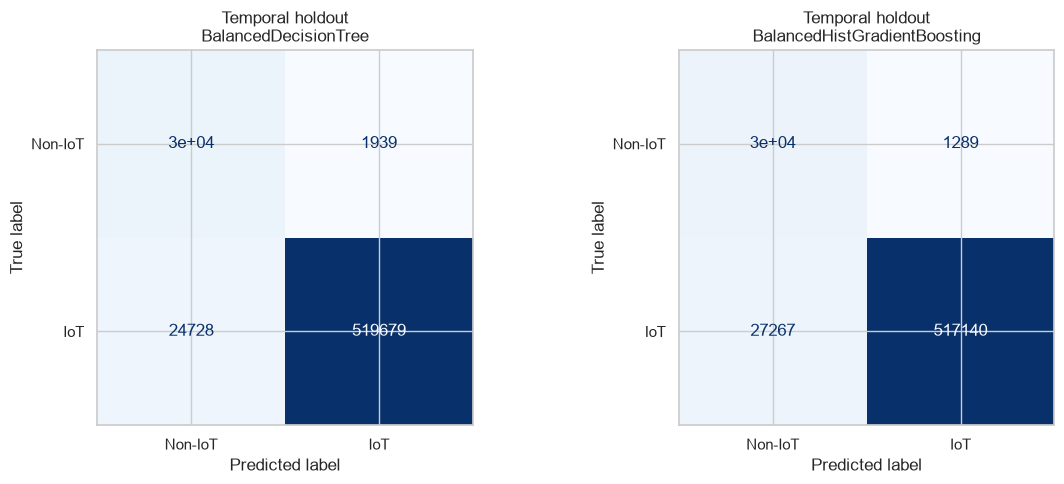

In [11]:
figure, axes = plt.subplots(1, len(temporal_models), figsize=(6 * len(temporal_models), 5))
if len(temporal_models) == 1:
    axes = [axes]

for axis, model_name in zip(axes, temporal_models):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        temporal_predictions[model_name],
        labels=[0, 1],
        display_labels=["Non-IoT", "IoT"],
        cmap="Blues",
        colorbar=False,
        ax=axis,
    )
    axis.set_title(f"Temporal holdout\n{model_name}")
plt.tight_layout()
plt.show()

## Per-device temporal errors and device-level aggregation

Window predictions are retained for detailed error attribution. A device-level
prediction is the mean IoT probability across all of that device's test
windows, thresholded at 0.5.

Temporal device-level accuracy: 95.833% (23/24)


,device_mac,device_name,label,label_name,windows,errors,mean_iot_probability,window_accuracy,device_prediction,device_correct
0,18:b4:30:25:be:e4,NEST Protect smoke alarm,1,IoT,34,20,0.459984,0.411765,0,False
1,30:8c:fb:b6:ea:45,Nest Dropcam,1,IoT,411,214,0.515069,0.479319,1,True
2,18:b7:9e:02:20:44,Triby Speaker,1,IoT,19894,10129,0.502657,0.490852,1,True
3,00:24:e4:1b:6f:96,Withings Smart scale,1,IoT,70,31,0.533339,0.557143,1,True
4,70:ee:50:03:b8:ac,Netatmo weather station,1,IoT,17762,5783,0.739366,0.674417,1,True
5,74:c6:3b:29:d7:1d,iHome,1,IoT,191,49,0.732677,0.743455,1,True
6,40:f3:08:ff:1e:da,Android Phone,0,Non-IoT,514,120,0.283658,0.766537,0,True
7,b4:ce:f6:a7:a3:c2,Android Phone,0,Non-IoT,1120,77,0.115144,0.931250,0,True
8,70:ee:50:18:34:43,Netatmo Welcome,1,IoT,50319,2950,0.906096,0.941374,1,True
9,74:2f:68:81:69:42,Laptop,0,Non-IoT,9266,505,0.072262,0.945500,0,True


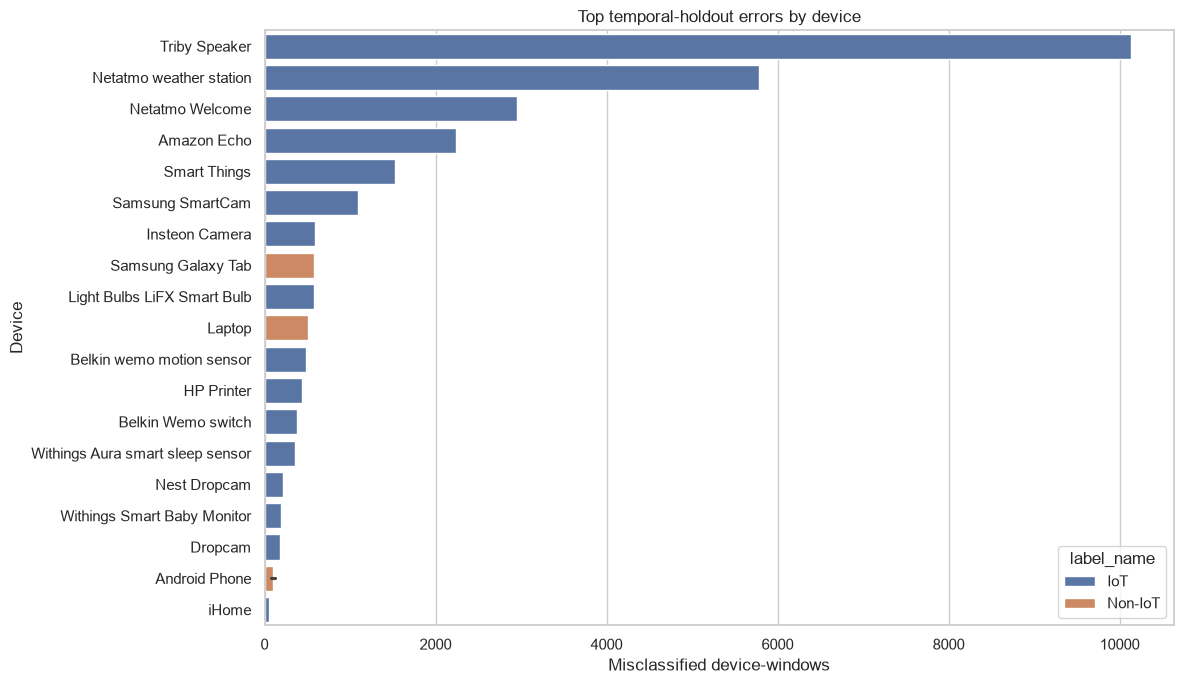

In [12]:
PRIMARY_MODEL_NAME = "BalancedHistGradientBoosting"
primary_predictions = temporal_predictions[PRIMARY_MODEL_NAME]
primary_probabilities = temporal_probabilities[PRIMARY_MODEL_NAME]

prediction_frame = test_set[
    ["source_file", "window", "device_mac", "device_name", "label", "label_name"]
].copy()
prediction_frame["prediction"] = primary_predictions
prediction_frame["iot_probability"] = primary_probabilities
prediction_frame["is_error"] = prediction_frame["label"] != prediction_frame["prediction"]

per_device = (
    prediction_frame.groupby(
        ["device_mac", "device_name", "label", "label_name"], as_index=False
    )
    .agg(
        windows=("label", "size"),
        errors=("is_error", "sum"),
        mean_iot_probability=("iot_probability", "mean"),
    )
)
per_device["window_accuracy"] = 1.0 - per_device["errors"] / per_device["windows"]
per_device["device_prediction"] = (
    per_device["mean_iot_probability"] >= 0.5
).astype("int8")
per_device["device_correct"] = per_device["device_prediction"] == per_device["label"]

device_level_accuracy = per_device["device_correct"].mean()
print(f"Temporal device-level accuracy: {device_level_accuracy:.3%} ({per_device['device_correct'].sum()}/{len(per_device)})")
display(per_device.sort_values(["device_correct", "window_accuracy", "windows"]).reset_index(drop=True))

error_by_device = per_device[per_device["errors"] > 0].sort_values(
    "errors", ascending=False
)
plt.figure(figsize=(12, 7))
sns.barplot(data=error_by_device.head(20), x="errors", y="device_name", hue="label_name")
plt.title("Top temporal-holdout errors by device")
plt.xlabel("Misclassified device-windows")
plt.ylabel("Device")
plt.tight_layout()
plt.show()

## Generalization to unseen devices

Five-fold stratified group cross-validation keeps every MAC address entirely
inside either training or validation for a fold. These results are expected
to be harder—and more operationally meaningful—than splitting windows from
already-known devices.

In [13]:
group_cv_rows = []

if RUN_GROUP_CV:
    X_all = features[FEATURE_COLUMNS].astype("float32")
    y_all = features["label"].to_numpy(dtype="int8")
    groups = features["device_mac"].to_numpy()
    splitter = StratifiedGroupKFold(
        n_splits=GROUP_CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    fold_indices = list(splitter.split(X_all, y_all, groups=groups))
    for fold, (train_indices, validation_indices) in enumerate(fold_indices, start=1):
        train_devices = set(groups[train_indices])
        validation_devices = set(groups[validation_indices])
        assert train_devices.isdisjoint(validation_devices)
        assert set(np.unique(y_all[train_indices])) == {0, 1}
        assert set(np.unique(y_all[validation_indices])) == {0, 1}

        for model_name, base_model in make_models(False).items():
            started = time.perf_counter()
            model = clone(base_model)
            model.fit(X_all.iloc[train_indices], y_all[train_indices])
            predictions = model.predict(X_all.iloc[validation_indices])
            probabilities = model.predict_proba(X_all.iloc[validation_indices])[:, 1]

            row = metric_row(y_all[validation_indices], predictions)
            validation_device_frame = pd.DataFrame(
                {
                    "device_mac": groups[validation_indices],
                    "label": y_all[validation_indices],
                    "iot_probability": probabilities,
                }
            )
            device_votes = validation_device_frame.groupby(
                ["device_mac", "label"], as_index=False
            ).agg(mean_iot_probability=("iot_probability", "mean"))
            device_votes["prediction"] = (
                device_votes["mean_iot_probability"] >= 0.5
            ).astype("int8")

            row.update(
                {
                    "fold": fold,
                    "model": model_name,
                    "train_devices": len(train_devices),
                    "validation_devices": len(validation_devices),
                    "device_accuracy": (
                        device_votes["prediction"] == device_votes["label"]
                    ).mean(),
                    "fit_and_predict_seconds": time.perf_counter() - started,
                }
            )
            group_cv_rows.append(row)
            print(
                f"Fold {fold}/{GROUP_CV_FOLDS} {model_name}: "
                f"balanced_accuracy={row['balanced_accuracy']:.4f}, "
                f"device_accuracy={row['device_accuracy']:.4f}, "
                f"seconds={row['fit_and_predict_seconds']:.1f}"
            )

    del X_all, y_all, groups

group_cv_results = pd.DataFrame(group_cv_rows)
if not group_cv_results.empty:
    display(group_cv_results)
    group_cv_summary = (
        group_cv_results.groupby("model")
        .agg(
            balanced_accuracy_mean=("balanced_accuracy", "mean"),
            balanced_accuracy_std=("balanced_accuracy", "std"),
            macro_f1_mean=("macro_f1", "mean"),
            macro_f1_std=("macro_f1", "std"),
            mcc_mean=("mcc", "mean"),
            mcc_std=("mcc", "std"),
            device_accuracy_mean=("device_accuracy", "mean"),
            device_accuracy_std=("device_accuracy", "std"),
            total_seconds=("fit_and_predict_seconds", "sum"),
        )
        .reset_index()
    )
    display(group_cv_summary)
else:
    print("Grouped cross-validation is disabled.")

Fold 1/5 BalancedDecisionTree: balanced_accuracy=0.6722, device_accuracy=0.6667, seconds=15.5


Fold 1/5 BalancedHistGradientBoosting: balanced_accuracy=0.4445, device_accuracy=0.6667, seconds=19.3


Fold 2/5 BalancedDecisionTree: balanced_accuracy=0.6211, device_accuracy=0.6000, seconds=17.8


Fold 2/5 BalancedHistGradientBoosting: balanced_accuracy=0.8214, device_accuracy=0.8000, seconds=18.9


Fold 3/5 BalancedDecisionTree: balanced_accuracy=0.6282, device_accuracy=0.8000, seconds=19.4


Fold 3/5 BalancedHistGradientBoosting: balanced_accuracy=0.6710, device_accuracy=0.8000, seconds=19.8


... (2 outputs left out)

Fold 5/5 BalancedDecisionTree: balanced_accuracy=0.7135, device_accuracy=0.5000, seconds=18.5


Fold 5/5 BalancedHistGradientBoosting: balanced_accuracy=0.7553, device_accuracy=0.6667, seconds=20.0


,accuracy,balanced_accuracy,mcc,macro_f1,precision_non_iot,recall_non_iot,f1_non_iot,precision_iot,recall_iot,f1_iot,fold,model,train_devices,validation_devices,device_accuracy,fit_and_predict_seconds
0,0.569071,0.672205,0.037150,0.367394,0.005138,0.775934,0.010209,0.998869,0.568477,0.724580,1,BalancedDecisionTree,24,6,0.666667,15.489094
1,0.078707,0.444524,-0.022252,0.073626,0.002521,0.812448,0.005026,0.993017,0.076599,0.142227,1,BalancedHistGradientBoosting,24,6,0.666667,19.301045
2,0.553824,0.621138,0.145471,0.462264,0.144874,0.705300,0.240373,0.942471,0.536976,0.684154,2,BalancedDecisionTree,25,5,0.600000,17.777662
3,0.857257,0.821389,0.484008,0.718713,0.392345,0.776544,0.521304,0.972109,0.866234,0.916123,2,BalancedHistGradientBoosting,25,5,0.800000,18.941005
4,0.479550,0.628157,0.101194,0.370694,0.058518,0.789789,0.108962,0.981434,0.466526,0.632427,3,BalancedDecisionTree,25,5,0.800000,19.442125
5,0.536027,0.671040,0.134564,0.404390,0.067310,0.817886,0.124383,0.985624,0.524194,0.684398,3,BalancedHistGradientBoosting,25,5,0.800000,19.753778
6,0.598579,0.750469,0.135219,0.409525,0.039339,0.908040,0.075412,0.997161,0.592897,0.743638,4,BalancedDecisionTree,22,8,0.625000,16.309817
7,0.602264,0.755698,0.138210,0.411567,0.039966,0.914871,0.076586,0.997387,0.596525,0.746548,4,BalancedHistGradientBoosting,22,8,0.625000,20.376496
8,0.502122,0.713472,0.063322,0.343226,0.010201,0.927187,0.020180,0.999191,0.499758,0.666272,5,BalancedDecisionTree,24,6,0.500000,18.540073
9,0.568726,0.755315,0.076357,0.373437,0.011968,0.943990,0.023635,0.999451,0.566640,0.723239,5,BalancedHistGradientBoosting,24,6,0.666667,19.973959


,model,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,mcc_mean,mcc_std,device_accuracy_mean,device_accuracy_std,total_seconds
0,BalancedDecisionTree,0.677088,0.055356,0.390621,0.046564,0.096471,0.046213,0.638333,0.109227,87.558770
1,BalancedHistGradientBoosting,0.689593,0.147023,0.396347,0.228522,0.162177,0.191240,0.711667,0.082412,98.346282


## Final interpretation

- The temporal holdout is the primary performance estimate for future traffic
  from the labeled devices.
- Grouped cross-validation is the stricter estimate for previously unseen
  devices and should not be expected to match window-level results.
- Infrastructure and unknown endpoints are deliberately not forced into the
  non-IoT class.
- Remaining errors should be interpreted through feature overlap, device
  rarity, and distribution shift rather than by pursuing a misleading 100%
  target.

In [14]:
best_temporal = temporal_results.iloc[0]
print(
    f"Best temporal model: {best_temporal['model']} | "
    f"accuracy={best_temporal['accuracy']:.4f} | "
    f"balanced_accuracy={best_temporal['balanced_accuracy']:.4f} | "
    f"macro_f1={best_temporal['macro_f1']:.4f} | "
    f"MCC={best_temporal['mcc']:.4f}"
)
print(f"Feature cache used: {feature_cache_path}")
print(f"Executed at: {datetime.now().isoformat(timespec='seconds')}")

Best temporal model: BalancedHistGradientBoosting | accuracy=0.9504 | balanced_accuracy=0.9546 | macro_f1=0.8269 | MCC=0.6909
Feature cache used: /Users/duongtuanhoang/simulated-desktop/learning/umsl-cybersecurity/summer2026/research-job/dataset/processed-data/feature-cache/phase1_bidirectional-v1_w5_91e0e9d543b7725e.parquet
Executed at: 2026-07-31T22:50:01
